# 04 · Distillation: let BERTurk teach the 2.6 MB tagger

**Katip lab, notebook 4.** Smoke test 5 minutes. Quick run about 1 hour on an Apple-silicon Mac
(most of it is fine-tuning BERTurk once). Needs notebook 2.

### The problem

Katip has two ends of a size scale and nothing proven in between:

* **BERTurk**, 110.8 MB: pretrained on billions of Turkish words, so it knows what Turkish looks like.
  Too big for GitHub Pages and slow in a browser.
* **Tiny-R**, 2.6 MB: trained from scratch on our data only. After notebook 2 it finds about half the
  names in real text.

### The hypothesis

A gold label says only *name* or *not a name*. A teacher's probabilities say **how name-like** each
word is (*Deniz* 0.6, *önemli* 0.001). That extra signal per word is what knowledge distillation
(Hinton et al., 2015) passes on. If BERTurk's knowledge of Turkish can flow into a tiny student this
way, the student should beat Tiny-R **at the same 2.6 MB**, on the same training text.

### Design

| step | what | cost |
| --- | --- | --- |
| A | **Teacher BERTurk-R**: fine-tune BERTurk on exactly Tiny-R's data (8,000 synthetic docs + 17,967 real sentences), names only | ~35 min (MPS) |
| B | the teacher writes down its beliefs (log-probabilities) for every word of that training text | ~5 min |
| C | **students**: tiny (2.6 MB) with distillation; in full mode also *mini* (~4.6 MB) and *small* (~7.6 MB) | ~7–15 min each |
| D | score on dev, pick each model's trust setting by notebook 2's rule | ~2 min |
| E | open Wiki NER test once: student vs Tiny-R (paired), and the size/accuracy chart | ~2 min |

The one comparison that answers the hypothesis is **tiny + distillation vs Tiny-R**: same size, same
text, same recipe, the only difference is the teacher's beliefs in the loss.

In [1]:
import json, os, pickle, random, time
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt
import katiplab as K
import distill as D

MODE = "smoke"     # "smoke": tiny data, 1 epoch, checks every step works (5 min). Then "quick", then optionally "full".
BASE = os.environ.get("KATIPLAB_TEACHER_BASE", "dbmdz/bert-base-turkish-cased")   # the BERTurk download (~440 MB, once)
DEVICE = "auto"    # mps on a Mac, cuda on NVIDIA, else cpu

STUDENTS = {"smoke": ["tiny"], "quick": ["tiny"], "full": ["tiny", "mini", "small"]}[MODE]
TEACHER_EPOCHS = {"smoke": 1, "quick": 2, "full": 3}[MODE]
TAG = "" if MODE != "smoke" else "_smoke"

sel = json.loads((K.RESULTS / "02_selected.json").read_text())
tiny_r_dir = K.ROOT / sel["model_dirs"][0]
print("Tiny-R from notebook 2:", tiny_r_dir.name, "trust", sel["trust"])

wiki = K.load_wiki("train"); random.Random(0).shuffle(wiki)      # the same shuffle and data as Tiny-R seed 0
synth = K.load_synth("train")
real_docs = K.pack(wiki[:sel["N"]])
if MODE == "smoke": synth, real_docs = synth[:300], real_docs[:100]
train_docs = list(synth) + list(real_docs)
print(f"mode {MODE}: {len(synth)} synthetic + {len(real_docs)} real pseudo-documents; students {STUDENTS}")

Tiny-R from notebook 2: tiny_real17967_seed0 trust 0.5
mode smoke: 300 synthetic + 100 real pseudo-documents; students ['tiny']


## 4.0 · Pre-registration

Written before any teacher or student exists (the smoke run writes to a separate file, so it cannot
spoil the real one).

| | hypothesis | pass if (Wiki NER test, step E) |
| --- | --- | --- |
| D1 | distillation helps at equal size | tiny student's pipeline name recall ≥ Tiny-R + **3 points**, McNemar p < 0.05 |
| D2 | nothing breaks | blind-set name recall ≥ **99.0%** |
| D3 | no new false alarms | ≤ **5** false names on name-free legal prose |
| D4 | still tiny | int8 ≤ **3.0 MB** |

Trust for every model is chosen on dev with notebook 2's rule (`D.choose_trust`).

In [2]:
prereg = K.RESULTS / f"04_prereg{TAG}.json"
if not prereg.exists():
    prereg.write_text(json.dumps({"written_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"), "mode": MODE, "base": BASE,
        "D1": "tiny student pipeline recall on Wiki NER test >= Tiny-R + 0.03, McNemar p < 0.05",
        "D2": "blind recall >= 0.990", "D3": "negatives false names <= 5", "D4": "int8 <= 3.0 MB",
        "students": STUDENTS, "teacher_epochs": TEACHER_EPOCHS, "kd_weight": 0.5, "temperature": 2.0}, indent=1))
print(prereg.read_text())

{
 "written_utc": "2026-11-12T01:47:52+00:00",
 "mode": "smoke",
 "base": "dbmdz/bert-base-turkish-cased",
 "D1": "tiny student pipeline recall on Wiki NER test >= Tiny-R + 0.03, McNemar p < 0.05",
 "D2": "blind recall >= 0.990",
 "D3": "negatives false names <= 5",
 "D4": "int8 <= 3.0 MB",
 "students": [
  "tiny"
 ],
 "teacher_epochs": 1,
 "kd_weight": 0.5,
 "temperature": 2.0
}


## 4.A · Teacher: BERTurk-R

Resumable: if the folder already holds a trained teacher, this cell only loads its info. The first run
downloads BERTurk from Hugging Face (about 440 MB, cached afterwards). On an M1–M3 expect 15–20
minutes per epoch.

In [3]:
teacher_dir = K.RUNS / f"teacher_berturk_r{TAG}"
if (teacher_dir / "train_info.json").exists():
    teacher_info = json.loads((teacher_dir / "train_info.json").read_text()); print("teacher already trained:", teacher_info)
else:
    teacher_info = D.train_teacher(teacher_dir, base=BASE, real_docs=real_docs, synth_docs=synth,
                                   epochs=TEACHER_EPOCHS, device=DEVICE)

/Users/f1k0/Development/Personal/Projects/active/katip/ml/berturk/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1112 02:47:57.161000 46893 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████| 197/197 [00:00<00:00, 9519.66it/s]
[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-base-turkish-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predict

teacher dbmdz/bert-base-turkish-cased on mps: 400 docs, 481 windows, 31 steps
  epoch 1/1 done (25s)


Writing model shards: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  2.02it/s]
/Users/f1k0/Development/Personal/Projects/active/katip/ml/berturk/.venv/lib/python3.13/site-packages/transformers/masking_utils.py:208: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if (padding_length := kv_length + kv_offset - attention_mask.shape[-1]) > 0:
/Users/f1k0/Development/Personal/Projects/active/katip/ml/berturk/.venv/lib/python3.13/site-packages/transformers/integrations/sdpa_attention.py:140: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means t

  saved teacher: int8 110.8 MB, 29 s


## 4.B · The teacher's beliefs

For every word of the training text, the teacher's log-probability of *O*, *B-PER* and *I-PER*.
Cached to `runs/` so students can be retrained without re-running the teacher.

In [4]:
cache = K.RUNS / f"soft_labels{TAG}.pkl"
if cache.exists():
    soft = pickle.loads(cache.read_bytes())
else:
    soft = D.soft_labels(teacher_dir, train_docs, device=DEVICE)
    cache.write_bytes(pickle.dumps(soft))
assert len(soft) == len(train_docs)
import numpy as np
ex = next(i for i, d in enumerate(real_docs) if any(t == "PERSON" for *_, t in d["spans"])) + len(synth)
words = [m.group() for m in D.WORD.finditer(train_docs[ex]["text"])]
print("what the teacher thinks, one real sentence (P(name)):")
print("  " + "  ".join(f"{w}:{1 - np.exp(soft[ex][k][0]):.2f}" for k, w in enumerate(words[:18])))

Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████| 199/199 [00:00<00:00, 8657.83it/s]


  teacher labels: 0/481 windows (0s)
what the teacher thinks, one real sentence (P(name)):
  Carnivàle:0.16  HBO:0.03  yapımı:0.01  televizyon:0.01  dizisi.:0.01  Gine'de:0.07  yer:0.00  alan:0.00  Fouta:0.08  Djallon:0.29  bölgesinden:0.01  doğan:0.00  ve:0.00  Gambiya'nın:0.07  başkenti:0.00  Banjul:0.17  kentinden:0.01  Atlas:0.00


## 4.C · Students

Same recipe as `ml/train.py` and Tiny-R (OneCycle, 5 epochs, own 16k WordPiece). Loss:
**½ · cross-entropy with the gold labels + ½ · T² · KL(teacher ‖ student)** at temperature T = 2.
The temperature softens both distributions so the student also learns from the teacher's small
probabilities, which is where the "how name-like" information sits.

In [5]:
student_dirs = {}
for arch in STUDENTS:
    out = K.RUNS / f"student_{arch}_kd{TAG}"
    if not (out / "train_info.json").exists():
        D.train_student(out, train_docs, soft=soft, arch=arch, kd_weight=0.5, temperature=2.0,
                        epochs=1 if MODE == "smoke" else 5)
    student_dirs[f"student {arch} (KD)"] = out
student_dirs




student tiny: 1,635,587 params · 400 docs · 418 windows · KD weight 0.5 · T 2.0
  epoch 1/1  loss 0.5024  (1s)


Writing model shards: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 246.06it/s]

  saved student_tiny_kd_smoke: int8 1.73 MB, 2 s


{'student tiny (KD)': PosixPath('/Users/f1k0/Development/Personal/Projects/active/katip/lab/runs/student_tiny_kd_smoke')}

## 4.D · Dev scores and trust settings

Every model, including the teacher and Tiny-R, gets its trust setting from the same dev rule.

In [6]:
dev_sets = {"wiki dev": K.load_wiki("dev"), "heldout": K.load_synth("heldout")}
contenders = {"Tiny-R (no teacher)": tiny_r_dir, **student_dirs, "teacher BERTurk-R": teacher_dir}
chosen, dev_rows = {}, []
for name, d in contenders.items():
    rows = D.dev_table(K.Tagger(d), dev_sets)
    trust, row = D.choose_trust(rows)
    chosen[name] = trust
    dev_rows += [{"model": name, **r} for r in rows]
    print(f"{name:22} trust {trust}  dev F2 {row['wiki dev f2']:.3f}  recall {row['wiki dev recall']:.3f}  precision {row['wiki dev precision']:.3f}")
pd.DataFrame(dev_rows).to_csv(K.RESULTS / f"04_dev_scores{TAG}.csv", index=False)

Tiny-R (no teacher)    trust 0.5  dev F2 0.524  recall 0.516  precision 0.559
student tiny (KD)      trust 0.9  dev F2 0.123  recall 0.103  precision 0.535
teacher BERTurk-R      trust 0.5  dev F2 0.491  recall 0.449  precision 0.783


## 4.E · The test, once

In [7]:
test_sets = {"wiki test": K.load_wiki("test"), "blind": K.load_synth("blind"), "negatives": K.load_synth("negatives")}
taggers = {n: K.Tagger(d) for n, d in contenders.items()}
taggers["Tiny (published)"] = K.Tagger(K.TINY); chosen["Tiny (published)"] = None
T = {n: K.evaluate(n, K.pipeline(t, trust=chosen[n]), test_sets) for n, t in taggers.items()}
rows = []
for n, by in T.items():
    rows.append({"model": n, "MB (int8)": round(taggers[n].size_mb, 2), "trust": chosen[n],
                 "wiki test recall": f"{by['wiki test']['recall']:.1%} [{by['wiki test']['recall_ci'][0]:.1%}–{by['wiki test']['recall_ci'][1]:.1%}]",
                 "wiki test precision": f"{by['wiki test']['precision']:.1%}", "blind recall": f"{by['blind']['recall']:.1%}",
                 "false names, name-free": by["negatives"]["false"], "ms/doc": round(by["wiki test"]["ms_per_doc"], 1)})
pd.DataFrame(rows).set_index("model")

,MB (int8),trust,wiki test recall,wiki test precision,blind recall,"false names, name-free",ms/doc
model,,,,,,,
Tiny-R (no teacher),2.57,0.5,55.5% [51.2%–60.1%],61.2%,99.5%,2,0.6
student tiny (KD),1.73,0.9,15.0% [11.0%–19.3%],71.6%,98.4%,2,0.6
teacher BERTurk-R,110.80,0.5,48.0% [43.4%–52.8%],85.0%,99.5%,2,16.3
Tiny (published),2.57,NaN,14.8% [11.1%–18.9%],69.6%,99.7%,2,0.7


In [8]:
A, B = T["Tiny-R (no teacher)"], T["student tiny (KD)"]
sig = K.paired_bootstrap(A["wiki test"]["_rows"][0], B["wiki test"]["_rows"][0])
print(f"tiny + teacher vs Tiny-R on real text: {100 * sig['diff']:+.1f} points (95% CI {100 * sig['ci'][0]:+.1f} to {100 * sig['ci'][1]:+.1f}), "
      f"found only by student {sig['only_b']}, only by Tiny-R {sig['only_a']}, McNemar p = {sig['p_mcnemar']:.2g}")
st = T["student tiny (KD)"]
verdict = {
    "D1 +3 pts vs Tiny-R, p<0.05": (sig["diff"] >= 0.03 and sig["p_mcnemar"] < 0.05, f"{100 * sig['diff']:+.1f} points, p={sig['p_mcnemar']:.2g}"),
    "D2 blind >= 99.0%": (st["blind"]["recall"] >= 0.99, f"{st['blind']['recall']:.1%}"),
    "D3 false names <= 5": (st["negatives"]["false"] <= 5, str(st["negatives"]["false"])),
    "D4 int8 <= 3.0 MB": (taggers["student tiny (KD)"].size_mb <= 3.0, f"{taggers['student tiny (KD)'].size_mb:.2f} MB"),
}
for h, (ok, v) in verdict.items(): print(f"{'PASS' if ok else 'FAIL'}  {h:30} {v}")

tiny + teacher vs Tiny-R on real text: -40.5 points (95% CI -45.4 to -35.6), found only by student 4, only by Tiny-R 269, McNemar p = 3e-74
FAIL  D1 +3 pts vs Tiny-R, p<0.05    -40.5 points, p=3e-74
FAIL  D2 blind >= 99.0%              98.4%
PASS  D3 false names <= 5            2
PASS  D4 int8 <= 3.0 MB              1.73 MB


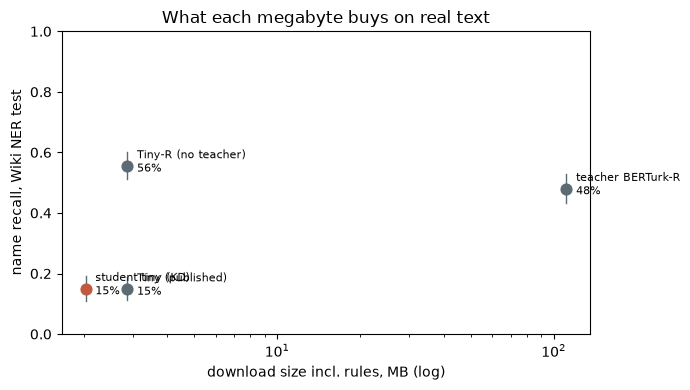

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
for n, t in taggers.items():
    r = T[n]["wiki test"]; mb = 0.3 + t.size_mb
    ax.scatter(mb, r["recall"], s=60, color="#c2593f" if "KD" in n else "#5b6b73", zorder=3)
    ax.plot([mb, mb], r["recall_ci"], color="#5b6b73", lw=1)
    ax.annotate(f"{n}\n{r['recall']:.0%}", (mb, r["recall"]), textcoords="offset points", xytext=(7, -4), fontsize=8)
ax.set_xscale("log"); ax.set_ylim(0, 1); ax.set_xlabel("download size incl. rules, MB (log)"); ax.set_ylabel("name recall, Wiki NER test")
ax.set_title("What each megabyte buys on real text"); plt.tight_layout()
plt.savefig(K.RESULTS / f"04_size_vs_recall{TAG}.png", dpi=160); plt.show()

In [10]:
best_student = "student tiny (KD)"
(K.RESULTS / f"04_student{TAG}.json").write_text(json.dumps({"dir": str(student_dirs[best_student].relative_to(K.ROOT)), "trust": chosen[best_student]}, indent=1))
(K.RESULTS / f"04_teacher{TAG}.json").write_text(json.dumps({"dir": str(teacher_dir.relative_to(K.ROOT)), "trust": chosen["teacher BERTurk-R"]}, indent=1))
slim = {n: {s: {k: v for k, v in r.items() if k != "_rows"} for s, r in by.items()} for n, by in T.items()}
(K.RESULTS / f"04_test{TAG}.json").write_text(json.dumps({"mode": MODE, "trust": chosen, "significance": sig, "systems": slim,
    "sizes_mb": {n: t.size_mb for n, t in taggers.items()}, "verdict": {h: [ok, v] for h, (ok, v) in verdict.items()}}, indent=1, ensure_ascii=False))
print("saved; notebook 5 will pick up the teacher and the student" + (" (smoke files are ignored there)" if TAG else ""))

saved; notebook 5 will pick up the teacher and the student (smoke files are ignored there)


## Reading the result

* **D1 passes**: the teacher's beliefs carry knowledge the labels don't, and a 2.6 MB model can hold
  some of it. Report "x% of BERTurk-R's real-text recall at 1/43 of the size".
* **D1 fails**: also a result. It says that at this size the bottleneck is capacity or vocabulary,
  not supervision. Then the *mini* and *small* students (full mode) show where the curve bends, and
  that is the size to ship if Pages can carry it.
* Either way the chart is the selling point: how much real-text recall each megabyte buys.

After the smoke run passes, set `MODE = "quick"` in the first code cell and run all cells again.